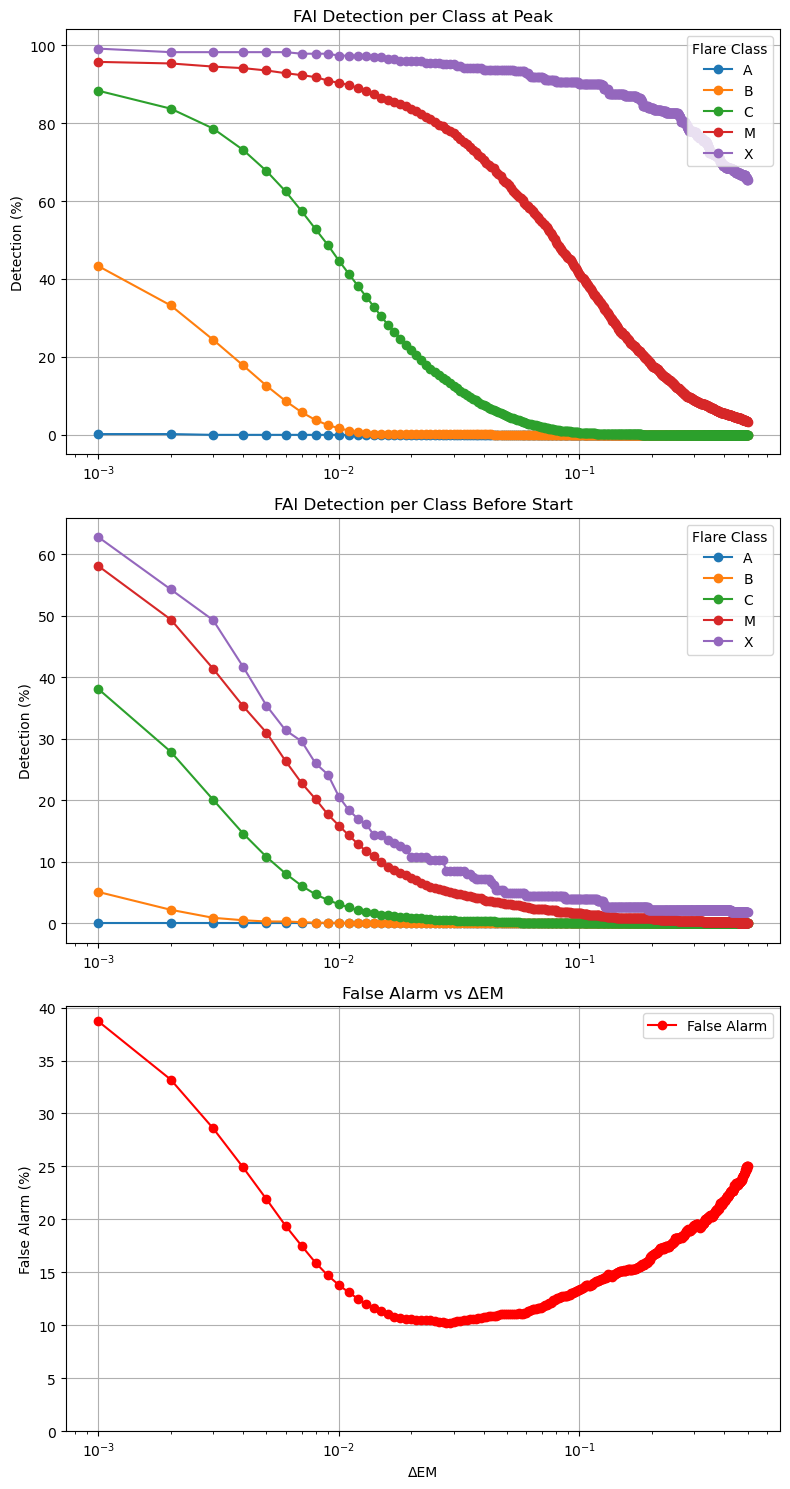

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1️⃣ Leer CSV global
# ----------------------------
csv_path = "FAI_global_summary_filteredend_nooverlap_2min_500.csv"
df = pd.read_csv(csv_path)

df['ΔEM'] = pd.to_numeric(df['ΔEM'])
df = df.sort_values('ΔEM')


# Clases de flare
flare_classes = ['A', 'B', 'C', 'M', 'X']

# ----------------------------
# 2️⃣ Crear figura con 3 subplots
# ----------------------------
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

# =============================
# a) Detección en el Peak
# =============================
ax = axes[0]
for cl in flare_classes:
    ax.plot(df['ΔEM'], df[f'{cl}_Peak'], marker='o', label=cl)
ax.set_ylabel("Detection (%)")
ax.set_xscale("log")
ax.set_title("FAI Detection per Class at Peak")
ax.grid(True)
ax.legend(title="Flare Class", loc="upper right")

# =============================
# b) Detección antes del Start
# =============================
ax = axes[1]
for cl in flare_classes:
    ax.plot(df['ΔEM'], df[f'{cl}_Start'], marker='o', label=cl)
ax.set_ylabel("Detection (%)")
ax.set_xscale("log")
ax.set_title("FAI Detection per Class Before Start")
ax.grid(True)
ax.legend(title="Flare Class", loc="upper right")

# =============================
# c) Falsos Negativos
# =============================
ax = axes[2]
if 'False Alarm (%)' in df.columns:
    ax.plot(df['ΔEM'], df['False Alarm (%)'], marker='o', color='red', label='False Alarm')
    ax.set_ylabel("False Alarm (%)")
    ax.set_xscale("log")
    ax.set_title("False Alarm vs ΔEM")
    ax.grid(True)
    ax.legend(loc="upper right")
    ax.set_ylim(0,)
else:
    ax.text(0.5, 0.5, "No column 'False Negative (%)' found", ha='center', va='center')
ax.set_xlabel("ΔEM")

plt.tight_layout()
plt.show()
